# Dynamic FER Confusion Matrices

Plot the image-sequence, FEA-sequence and intermediate-fusion confusion matrices from the test predictions in `emohevrdb-dfer`. The CSV is read from a fixed repository commit.

Requirements: NumPy, pandas, seaborn, and Matplotlib. Run all cells in order. The three generated PDFs are saved in the working directory.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load predictions

In [2]:
COMMIT = "3993b6813443e75eff8f380e9d4c1b1d6810221c"
CSV_URL = (
    "https://raw.githubusercontent.com/thorbenortmann/emohevrdb-dfer/"
    f"{COMMIT}/5_dynamic_facial_expression_recognition/dynamic_test_predictions.csv"
)

predictions = pd.read_csv(CSV_URL)
CLASS_NAMES = ["Anger", "Disgust", "Fear", "Happiness", "Neutral", "Sadness", "Surprise"]

## Calculate confusion matrices

Image and intermediate-fusion predictions use 756 camera-specific samples. FEA predictions use 378 reenactments, counted once each.


In [3]:
def confusion_matrix(records, prediction_column):
    matrix = np.zeros((7, 7), dtype=int)
    np.add.at(
        matrix,
        (records["true_label_id"].to_numpy(), records[prediction_column].to_numpy()),
        1,
    )
    return matrix


# FEA predictions are repeated for the two camera views of each reenactment.
fea_predictions = predictions.drop_duplicates("reenactment_id")

matrices = {
    "di_confusion_matrix.pdf": confusion_matrix(predictions, "image_pred_id"),
    "dfea_confusion_matrix.pdf": confusion_matrix(fea_predictions, "fea_pred_id"),
    "dmul_confusion_matrix.pdf": confusion_matrix(predictions, "multimodal_pred_id"),
}

for filename, matrix in matrices.items():
    correct = matrix.trace()
    total = matrix.sum()
    print(f"{filename}: {correct}/{total} correct ({correct / total:.2%})")

di_confusion_matrix.pdf: 550/756 correct (72.75%)
dfea_confusion_matrix.pdf: 296/378 correct (78.31%)
dmul_confusion_matrix.pdf: 617/756 correct (81.61%)


## Plot and export

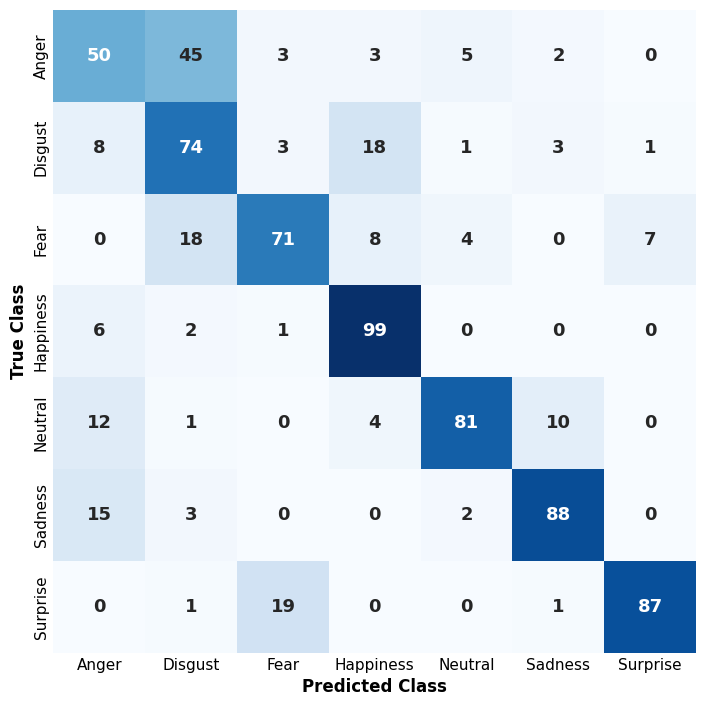

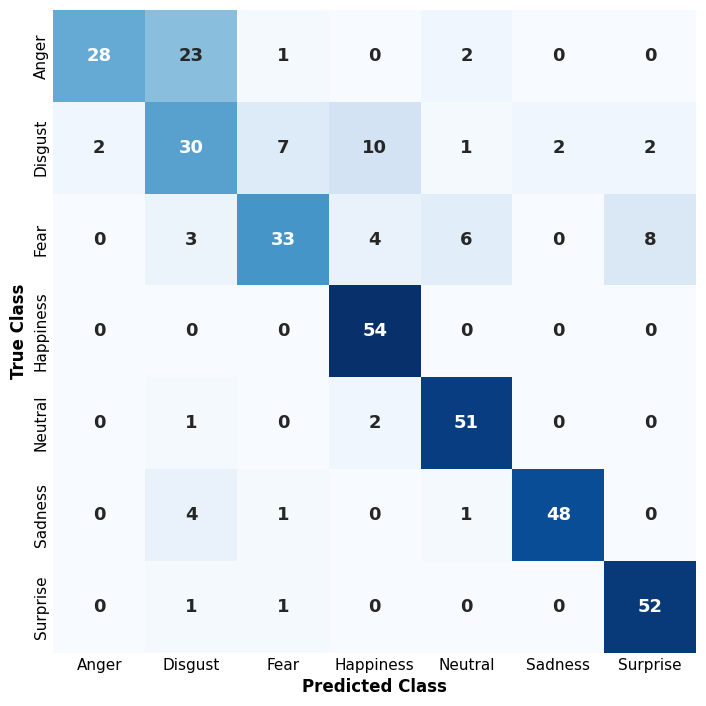

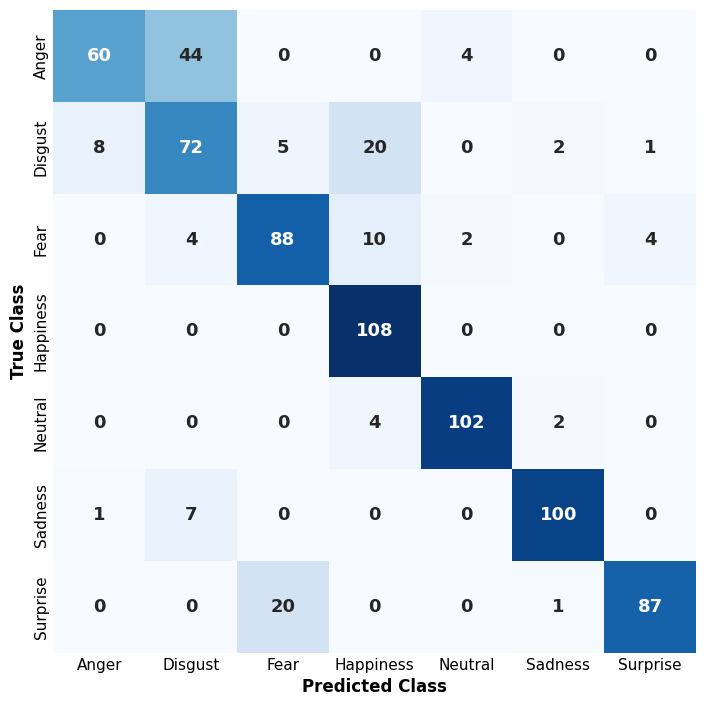

In [4]:
def plot_confusion_matrix(matrix, filename):
    with plt.rc_context({"font.family": "DejaVu Sans", "pdf.fonttype": 3}):
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.pcolormesh(matrix, cmap="Blues", vmin=0, vmax=matrix.max(), shading="flat")
        ax.set_xlim(0, 7)
        ax.set_ylim(7, 0)
        ax.set_aspect("equal")

        positions = np.arange(7) + 0.5
        ax.set_xticks(positions, CLASS_NAMES, fontsize=11)
        ax.set_yticks(positions, CLASS_NAMES, fontsize=11, rotation=90, va="center")
        ax.set_xlabel("Predicted Class", fontsize=12, fontweight="bold")
        ax.set_ylabel("True Class", fontsize=12, fontweight="bold")
        ax.tick_params(axis="both", length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

        threshold = matrix.max() / 2
        for row in range(7):
            for column in range(7):
                value = matrix[row, column]
                ax.text(
                    column + 0.5, row + 0.5, str(value),
                    ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if value > threshold else "#262626",
                )

        fig.tight_layout(pad=0.5)
        fig.savefig(filename, format="pdf", bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)


for filename, matrix in matrices.items():
    plot_confusion_matrix(matrix, filename)